# Script to make 2D Plume Height VS Time from NAME Input ESP

In [1]:
import re
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timedelta

class ESP_PlumeDataPlotter:
    def __init__(self, file_path):
        self.file_path = file_path
        self.metadata = {}
        self.emission_data = []
        self.simulation_start = None

    def _parse_metadata(self, lines):
        for line in lines:
            if "simulationStartDatetime" in line:
                value = line.split()[-1].strip()
                self.metadata["Simulation Start"] = value
                self.simulation_start = datetime.strptime(value, "%Y%m%d_%H%M")
            elif "simulationDurationInHour" in line:
                self.metadata["Duration (hr)"] = int(line.split()[-1].strip())
            elif "volcanoName" in line:
                self.metadata["Volcano Name"] = line.split()[-1].strip()
            elif "volcanoX" in line:
                self.metadata["Volcano X"] = float(line.split()[-1].strip())
            elif "volcanoY" in line:
                self.metadata["Volcano Y"] = float(line.split()[-1].strip())
            elif "summitHeightInMetre" in line:
                self.metadata["Summit Height (m)"] = int(line.split()[-1].strip())
            elif "simulationDomain_xMin" in line:
                self.metadata["Domain X Min"] = float(line.split()[-1].strip())
            elif "simulationDomain_xMax" in line:
                self.metadata["Domain X Max"] = float(line.split()[-1].strip())
            elif "simulationDomain_yMin" in line:
                self.metadata["Domain Y Min"] = float(line.split()[-1].strip())
            elif "simulationDomain_yMax" in line:
                self.metadata["Domain Y Max"] = float(line.split()[-1].strip())
            elif "outputGridSize_dX" in line:
                self.metadata["Grid Size dX"] = float(line.split()[-1].strip())
            elif "outputGridSize_dY" in line:
                self.metadata["Grid Size dY"] = float(line.split()[-1].strip())

    def _parse_emission_data_from_txt(self, lines):
        pattern = re.compile(r"emissionSourceParameterSet_\d+\s+(\d+)_01_00_(\d{4}_\d{2}_\d{2}_\d{2}_\d{2})")
        for line in lines:
            match = pattern.search(line.strip())
            if match:
                height = int(match.group(1))
                timestamp = datetime.strptime(match.group(2), "%Y_%m_%d_%H_%M")
                cumulative_time = (timestamp - self.simulation_start).total_seconds() / 3600
                self.emission_data.append((cumulative_time, height, timestamp.strftime("%H:%M")))

    def _parse_emission_data_from_csv(self):
        df = pd.read_csv(self.file_path)
        df.columns = df.columns.str.strip()  # Clean headers
        for _, row in df.iterrows():
            height = int(row["plume height from summit (m)"])
            timestamp = datetime.strptime(row["start time (UTC)"], "%Y%m%d_%H%M")
            if not self.simulation_start:
                self.simulation_start = datetime.strptime("20200112_0500", "%Y%m%d_%H%M")
            cumulative_time = (timestamp - self.simulation_start).total_seconds() / 3600
            self.emission_data.append((cumulative_time, height, timestamp.strftime("%H:%M")))

    def load_data(self):
        if self.file_path.endswith(".txt"):
            with open(self.file_path, "r") as file:
                lines = file.readlines()
            self._parse_metadata(lines)
            self._parse_emission_data_from_txt(lines)
        elif self.file_path.endswith(".csv"):
            self._parse_emission_data_from_csv()
        else:
            raise ValueError("Unsupported file format. Only .txt and .csv are supported.")

    def plot(self, save_path=None):
        cumulative_times, heights, actual_times = zip(*self.emission_data)

        fig, ax1 = plt.subplots(figsize=(12, 6))
        ax1.plot(cumulative_times, heights, marker='o')
        ax1.set_xlabel("Cumulative Time (Hours)")
        ax1.set_ylabel("Plume Height (Meters)")
        ax1.set_title("Plume Height vs. Cumulative Time")
        ax1.grid(True)

        # Secondary axis
        ax2 = ax1.twiny()
        ax2.set_xlim(ax1.get_xlim())
        ax2.set_xticks(cumulative_times)
        ax2.set_xticklabels(actual_times, rotation=45)
        ax2.set_xlabel("Actual Time (HH:MM)")

        # Metadata sidebar
        if self.metadata:
            metadata_text = "\n".join([f"{k}: {v}" for k, v in self.metadata.items()])
            props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
            ax1.text(1.05, 0.5, metadata_text, transform=ax1.transAxes, fontsize=10,
                     verticalalignment='center', bbox=props)

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path)
        plt.show()


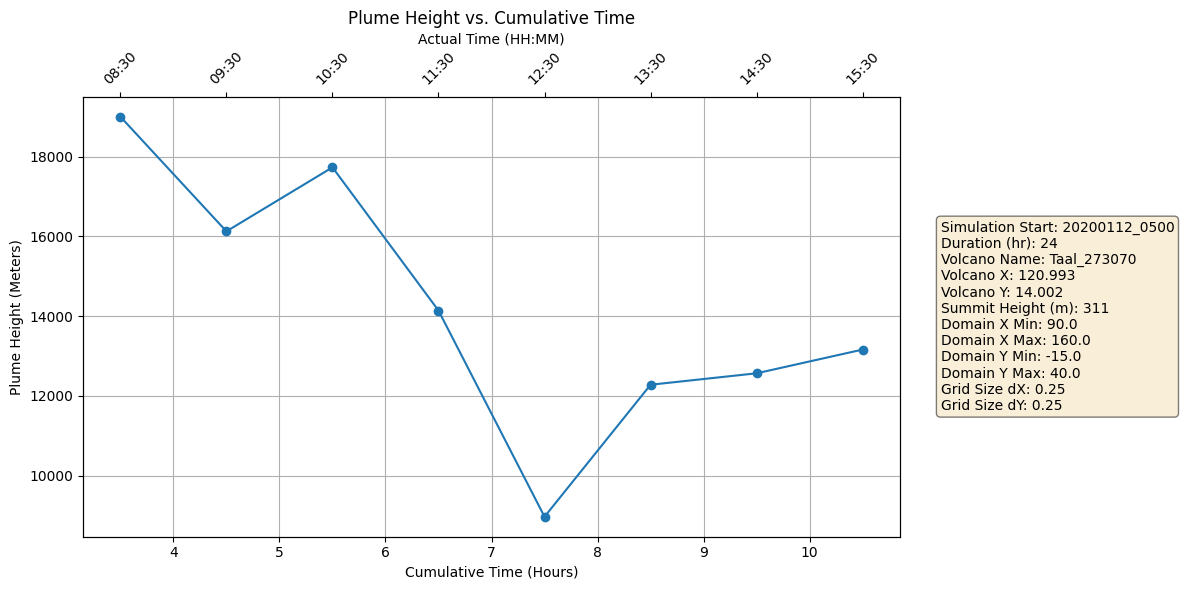

In [2]:
plotter = ESP_PlumeDataPlotter("../Taal_273070_20200112_scenario_infrasound_evolution.txt")
plotter.load_data()
plotter.plot(save_path="plume_plot_from_txt.png")


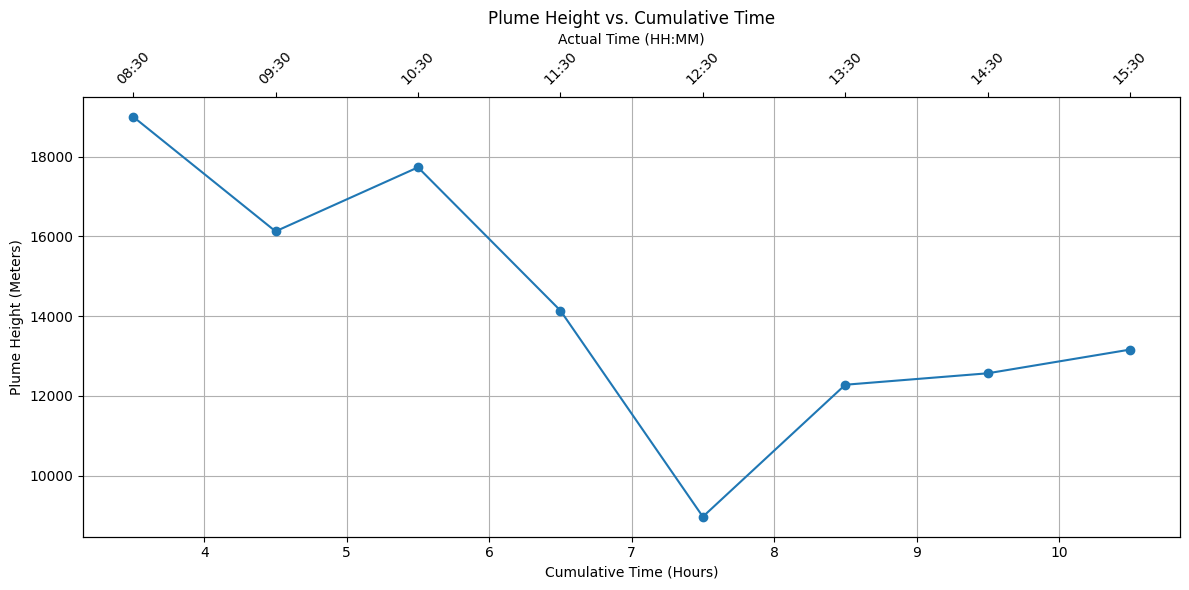

In [3]:
plotter = ESP_PlumeDataPlotter("emissionSourceParameters.csv")
plotter.load_data()
plotter.plot(save_path="plume_plot_from_csv.png")
